# 🌍 World Happiness Report — Professional Data Science Project

**Author:** Data Analysis Pipeline  
**Dataset:** World Happiness Report (2005–2022)  
**Target:** `Life Ladder` — Cantril ladder happiness score (0-10)

---

### Project Structure
| # | Section | What we do |
|---|---------|-----------|
| 0 | Setup | Install deps, set seeds, configure style |
| 1 | Data Loading | Load, rename, first look |
| 2 | Data Quality | Missing values heatmap, smart imputation |
| 3 | Outlier Detection | IQR fencing, Z-score analysis |
| 4 | Feature Engineering | Happiness tiers, YoY change, interaction terms |
| 5 | EDA | Distributions, regions, trends, COVID impact, movers |
| 6 | Statistical Testing | ANOVA between regions, Pearson p-values |
| 7 | Clustering | K-Means, Elbow method, cluster profiling |
| 8 | ML Pipelines | Tuned Linear / Ridge / RF / GBM with cross-validation |
| 9 | Model Explainability | SHAP values, learning curves, residuals |
| 10 | Executive Summary | Key findings in plain language |

---
## 0. Setup & Reproducibility

In [1]:
# Install any missing libraries (safe to re-run)
import subprocess, sys

LIBS = ['shap', 'scipy', 'scikit-learn']
for lib in LIBS:
    try:
        __import__(lib.replace('-','_'))
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', lib, '-q'])

print('Environment ready ✅')

Environment ready ✅


In [2]:
import warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import scipy.stats as stats
import shap

from sklearn.pipeline          import Pipeline
from sklearn.compose           import ColumnTransformer
from sklearn.preprocessing     import StandardScaler, LabelEncoder
from sklearn.model_selection   import (train_test_split, cross_val_score,
                                        KFold, RandomizedSearchCV, learning_curve)
from sklearn.linear_model      import LinearRegression, Ridge, Lasso
from sklearn.ensemble          import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics           import (mean_squared_error, r2_score,
                                        mean_absolute_error)
from sklearn.cluster           import KMeans
from sklearn.decomposition     import PCA

warnings.filterwarnings('ignore')

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# ── Global aesthetics ────────────────────────────────────────────────────────
PALETTE = 'Set2'
sns.set_theme(style='whitegrid', palette=PALETTE, font_scale=1.1)
plt.rcParams.update({
    'figure.dpi'     : 130,
    'axes.titlesize' : 13,
    'axes.labelsize' : 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

FEATURE_COLS = ['LGPC','SS','HLEB','FMLC','Generosity',
                'POC','Positive Affect','Negative Affect','CING']

TARGET = 'Life Ladder'

FEATURE_LABELS = {
    'LGPC' : 'Log GDP/Capita',
    'SS'   : 'Social Support',
    'HLEB' : 'Healthy Life Exp.',
    'FMLC' : 'Freedom',
    'Generosity' : 'Generosity',
    'POC'  : 'Corruption Perception',
    'Positive Affect' : 'Positive Affect',
    'Negative Affect' : 'Negative Affect',
    'CING' : 'Gov. Confidence',
}

print('All imports OK ✅  |  SEED =', SEED)

All imports OK ✅  |  SEED = 42


---
## 1. Data Loading & First Look

> **⚠️ Change `CSV_PATH` below to your file location before running.**

In [3]:
# ─── SET YOUR PATH HERE ──────────────────────────────────────────────────
CSV_PATH = r"data/World Happiness Report.csv"
# ──────────────────────────────────────────────────────────────────────────

df_raw = pd.read_csv(CSV_PATH)

# Rename verbose columns
df_raw = df_raw.rename(columns={
    'Log GDP Per Capita'               : 'LGPC',
    'Social Support'                   : 'SS',
    'Healthy Life Expectancy At Birth' : 'HLEB',
    'Freedom To Make Life Choices'     : 'FMLC',
    'Perceptions Of Corruption'        : 'POC',
    'Confidence In National Government': 'CING',
})

print(f'Shape : {df_raw.shape}')
print(f'Years : {df_raw["Year"].min()} - {df_raw["Year"].max()}')
print(f'Countries : {df_raw["Country Name"].nunique()}')
df_raw.head(4)

Shape : (2199, 13)
Years : 2005 - 2022
Countries : 165


,Country Name,Regional Indicator,Year,Life Ladder,LGPC,SS,HLEB,FMLC,Generosity,POC,Positive Affect,Negative Affect,CING
0,Afghanistan,South Asia,2008,3.723590,7.350416,0.450662,50.500000,0.718114,0.167652,0.881686,0.414297,0.258195,0.612072
1,Afghanistan,South Asia,2009,4.401778,7.508646,0.552308,50.799999,0.678896,0.190809,0.850035,0.481421,0.237092,0.611545
2,Afghanistan,South Asia,2010,4.758381,7.613900,0.539075,51.099998,0.600127,0.121316,0.706766,0.516907,0.275324,0.299357
3,Afghanistan,South Asia,2011,3.831719,7.581259,0.521104,51.400002,0.495901,0.163571,0.731109,0.479835,0.267175,0.307386


In [4]:
df_raw.describe().T.round(3).style.background_gradient(cmap='Blues', axis=0)

,count,mean,std,min,25%,50%,75%,max
Year,2199.000000,2014.161000,4.719000,2005.000000,2010.000000,2014.000000,2018.000000,2022.000000
Life Ladder,2199.000000,5.479000,1.126000,1.281000,4.647000,5.432000,6.309000,8.019000
LGPC,2179.000000,9.390000,1.153000,5.527000,8.500000,9.499000,10.373000,11.664000
SS,2186.000000,0.811000,0.121000,0.228000,0.747000,0.836000,0.905000,0.987000
HLEB,2145.000000,63.295000,6.901000,6.720000,59.120000,65.050000,68.500000,74.475000
FMLC,2166.000000,0.748000,0.140000,0.258000,0.657000,0.770000,0.859000,0.985000
Generosity,2126.000000,0.000000,0.161000,-0.338000,-0.112000,-0.023000,0.092000,0.703000
POC,2083.000000,0.745000,0.186000,0.035000,0.688000,0.800000,0.869000,0.983000
Positive Affect,2175.000000,0.652000,0.106000,0.179000,0.572000,0.663000,0.738000,0.884000
Negative Affect,2183.000000,0.272000,0.087000,0.083000,0.208000,0.261000,0.323000,0.705000


---
## 2. Data Quality & Missing Value Strategy

Missing values are handled per-column with a **two-pass strategy**:
1. Numeric columns → fill with **regional median** (preserves regional heterogeneity)
2. Rows still missing `Regional Indicator` → drop (only ~5% of data)

This retains ~95% of rows vs ~23% loss from naive `dropna`.

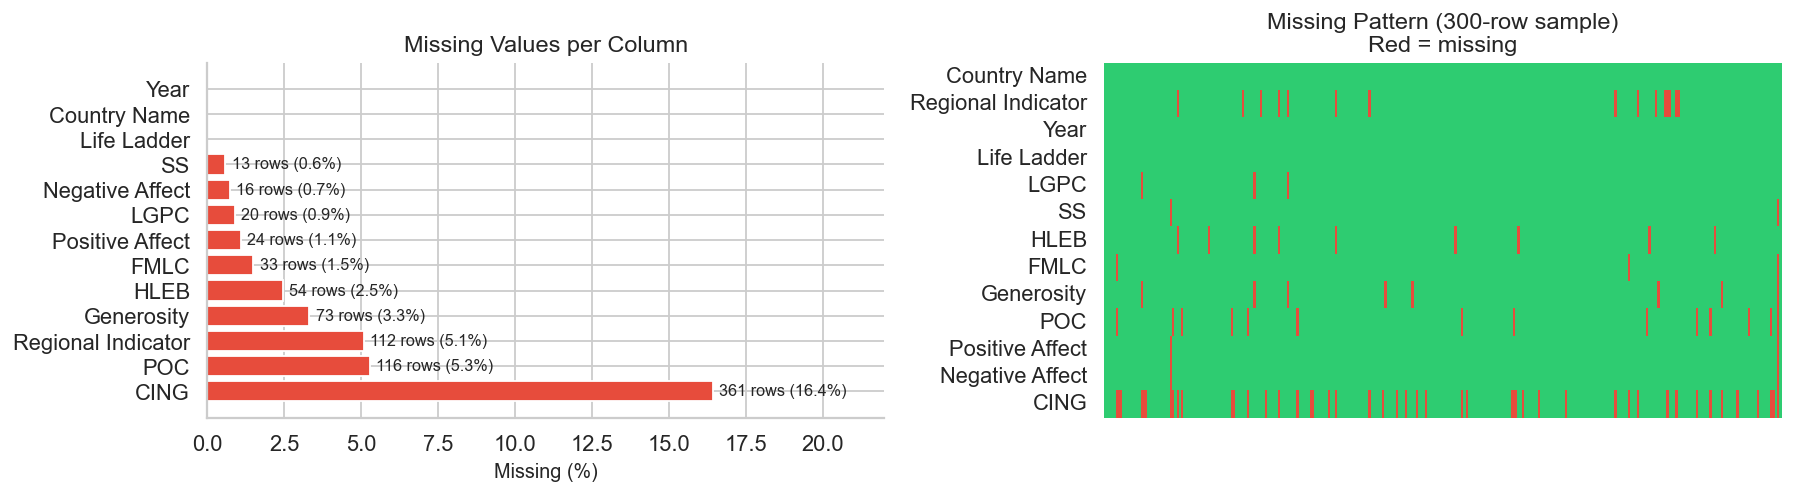

In [5]:
# ── Missing value heatmap ────────────────────────────────────────────────────
missing = df_raw.isnull().sum().sort_values(ascending=False)
missing_pct = missing / len(df_raw) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Bar chart
colors = ['#e74c3c' if v > 0 else '#2ecc71' for v in missing]
axes[0].barh(missing.index, missing_pct.values, color=colors, edgecolor='white')
for i, (v, pct) in enumerate(zip(missing.values, missing_pct.values)):
    if v > 0:
        axes[0].text(pct + 0.2, i, f'{v} rows ({pct:.1f}%)', va='center', fontsize=9)
axes[0].set_xlabel('Missing (%)')
axes[0].set_title('Missing Values per Column')
axes[0].set_xlim(0, 22)

# Heatmap of missing patterns (sample 300 rows)
sample_miss = df_raw.isnull().astype(int).sample(300, random_state=SEED)
sns.heatmap(sample_miss.T, cbar=False, ax=axes[1],
            cmap=['#2ecc71','#e74c3c'], yticklabels=True, xticklabels=False)
axes[1].set_title('Missing Pattern (300-row sample)\nRed = missing')

plt.tight_layout()
plt.show()

In [6]:
df = df_raw.copy()

# Pass 1 — fill numerics with regional median
for col in FEATURE_COLS:
    group_med  = df.groupby('Regional Indicator')[col].transform('median')
    global_med = df[col].median()
    df[col] = df[col].fillna(group_med).fillna(global_med)

# Pass 2 — drop rows without a region (cannot impute fairly)
df.dropna(subset=['Regional Indicator'], inplace=True)
df.reset_index(drop=True, inplace=True)

print(f'Rows kept  : {len(df)} / {len(df_raw)}  ({100*len(df)/len(df_raw):.1f}%)')
print(f'Remaining NaN : {df.isnull().sum().sum()}')
df.dtypes

Rows kept  : 2087 / 2199  (94.9%)
Remaining NaN : 0


Country Name           object
Regional Indicator     object
Year                    int64
Life Ladder           float64
LGPC                  float64
SS                    float64
HLEB                  float64
FMLC                  float64
Generosity            float64
POC                   float64
Positive Affect       float64
Negative Affect       float64
CING                  float64
dtype: object

---
## 3. Outlier Detection & Treatment

We use **IQR fencing** (1.5×IQR rule) to flag outliers per numeric column.  
We do NOT remove them — happiness data has legitimate extreme values (war zones, etc.)  
but we document them and cap only the most extreme cases using **Winsorisation at 1% / 99%**.

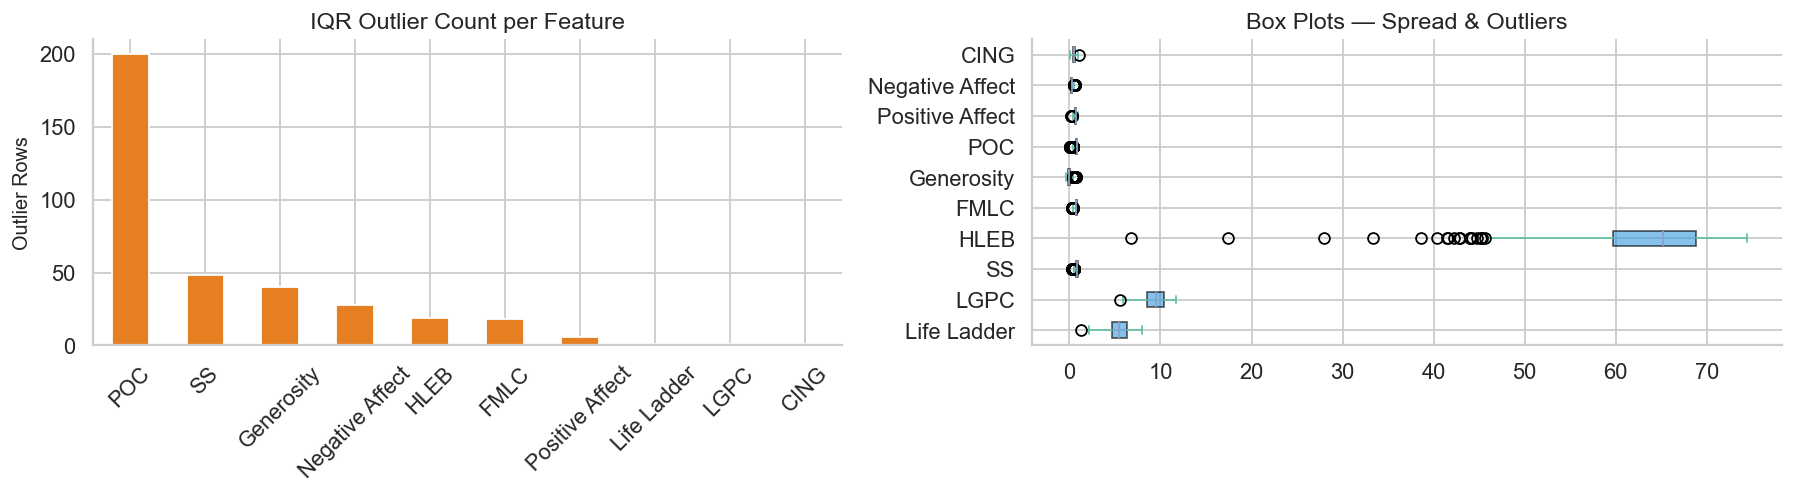


Outlier counts:
 POC                200
SS                  48
Generosity          40
Negative Affect     28
HLEB                19
FMLC                18
Positive Affect      6
Life Ladder          1
LGPC                 1
CING                 1
dtype: int64


In [7]:
# ── IQR-based outlier count per feature ─────────────────────────────────────
def iqr_outlier_count(series):
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    return ((series < Q1 - 1.5*IQR) | (series > Q3 + 1.5*IQR)).sum()

outlier_counts = {col: iqr_outlier_count(df[col]) for col in [TARGET] + FEATURE_COLS}
outlier_df = pd.Series(outlier_counts).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Outlier counts bar
outlier_df.plot(kind='bar', ax=axes[0], color='#e67e22', edgecolor='white')
axes[0].set_title('IQR Outlier Count per Feature')
axes[0].set_ylabel('Outlier Rows')
axes[0].tick_params(axis='x', rotation=45)

# Box plots for all features
df[[TARGET] + FEATURE_COLS].plot(
    kind='box', ax=axes[1], vert=False,
    patch_artist=True,
    boxprops=dict(facecolor='#3498db', alpha=0.6)
)
axes[1].set_title('Box Plots — Spread & Outliers')

plt.tight_layout()
plt.show()
print('\nOutlier counts:\n', outlier_df)

In [8]:
# ── Winsorise at 1st / 99th percentile (caps, doesn't remove) ───────────────
df_model = df.copy()   # keep df_model clean for ML; keep df intact for EDA

for col in FEATURE_COLS:
    lo = df_model[col].quantile(0.01)
    hi = df_model[col].quantile(0.99)
    df_model[col] = df_model[col].clip(lo, hi)

print('Winsorisation applied to df_model ✅')
print(f'Rows unchanged: {len(df_model)}')

Winsorisation applied to df_model ✅
Rows unchanged: 2087


---
## 4. Feature Engineering

We create meaningful derived features that could improve model performance  
and provide additional analytical angles.

In [9]:
# ── 4.1  Happiness Tier (quartile-based label) ──────────────────────────────
quartiles = df[TARGET].quantile([0.25, 0.5, 0.75])
def happiness_tier(score):
    if score <= quartiles[0.25]: return 'Low'
    elif score <= quartiles[0.50]: return 'Medium-Low'
    elif score <= quartiles[0.75]: return 'Medium-High'
    else: return 'High'

df['Happiness_Tier']       = df[TARGET].apply(happiness_tier)
df_model['Happiness_Tier'] = df_model[TARGET].apply(happiness_tier)

# ── 4.2  Year-over-Year change per country ───────────────────────────────────
df = df.sort_values(['Country Name','Year'])
df['YoY_Change'] = df.groupby('Country Name')[TARGET].diff()

df_model = df_model.sort_values(['Country Name','Year'])
df_model['YoY_Change'] = df_model.groupby('Country Name')[TARGET].diff().fillna(0)

# ── 4.3  COVID year flag ─────────────────────────────────────────────────────
df['COVID_Year']       = (df['Year'] == 2020).astype(int)
df_model['COVID_Year'] = (df_model['Year'] == 2020).astype(int)

# ── 4.4  Interaction features ────────────────────────────────────────────────
# Wealthy AND social:  high GDP × high social support
df_model['GDP_x_SS']       = df_model['LGPC'] * df_model['SS']
# Freedom adjusted for corruption
df_model['Freedom_Adj']    = df_model['FMLC'] * (1 - df_model['POC'])
# Emotional balance
df_model['Affect_Balance'] = df_model['Positive Affect'] - df_model['Negative Affect']

# ── 4.5  Decade grouping ─────────────────────────────────────────────────────
df['Decade']       = (df['Year'] // 5) * 5
df_model['Decade'] = (df_model['Year'] // 5) * 5

print('New features created:')
new_feats = ['Happiness_Tier','YoY_Change','COVID_Year','GDP_x_SS',
             'Freedom_Adj','Affect_Balance','Decade']
print(df[new_feats].head(3).to_string())

New features created:


KeyError: "['GDP_x_SS', 'Freedom_Adj', 'Affect_Balance'] not in index"

In [ ]:
# ── Correlation of engineered features with target ───────────────────────────
eng_features = ['GDP_x_SS','Freedom_Adj','Affect_Balance','YoY_Change','COVID_Year']

corr_eng = df_model[eng_features + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 3))
colors = ['#2ecc71' if v > 0 else '#e74c3c' for v in corr_eng]
ax.barh(corr_eng.index, corr_eng.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Engineered Feature Correlation with Happiness Score')
ax.set_xlabel('Pearson r')
plt.tight_layout()
plt.show()

---
## 5. Exploratory Data Analysis

### 5.1 Target Distribution

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Histogram + KDE
sns.histplot(df[TARGET], kde=True, bins=35, ax=axes[0], color='#3498db')
axes[0].axvline(df[TARGET].mean(),   color='red',    ls='--', label=f"Mean  {df[TARGET].mean():.2f}")
axes[0].axvline(df[TARGET].median(), color='orange', ls='--', label=f"Median {df[TARGET].median():.2f}")
axes[0].legend(fontsize=9)
axes[0].set_title('Happiness Score Distribution')
axes[0].set_xlabel('Life Ladder')

# QQ-plot to check normality
from scipy.stats import probplot
probplot(df[TARGET], dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot (Normality Check)')

# By tier
tier_order = ['Low','Medium-Low','Medium-High','High']
tier_counts = df['Happiness_Tier'].value_counts().reindex(tier_order)
axes[2].bar(tier_counts.index, tier_counts.values,
            color=sns.color_palette('RdYlGn', 4), edgecolor='white')
axes[2].set_title('Count per Happiness Tier')
axes[2].set_ylabel('Count')
for i, v in enumerate(tier_counts.values):
    axes[2].text(i, v + 5, str(v), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

sk = stats.skew(df[TARGET])
kt = stats.kurtosis(df[TARGET])
_, p_norm = stats.shapiro(df[TARGET].sample(500, random_state=SEED))
print(f'Skewness: {sk:.3f}  |  Kurtosis: {kt:.3f}  |  Shapiro-Wilk p={p_norm:.4f}')
print('Distribution is NOT normal' if p_norm < 0.05 else 'Distribution approximates normal')

### 5.2 Regional Analysis

In [ ]:
region_stats = (
    df.groupby('Regional Indicator')[TARGET]
    .agg(Mean='mean', Median='median', Std='std', Count='count')
    .sort_values('Median', ascending=False)
    .round(3)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Horizontal bar — median per region
palette_r = sns.color_palette(PALETTE, len(region_stats))
region_stats['Median'].plot(kind='barh', ax=axes[0], color=palette_r)
axes[0].set_title('Median Happiness by Region')
axes[0].set_xlabel('Median Life Ladder')
axes[0].invert_yaxis()
for i, v in enumerate(region_stats['Median']):
    axes[0].text(v + 0.03, i, f'{v:.2f}', va='center', fontsize=9)

# Violin — distribution shape per region
order = region_stats.index.tolist()
sns.violinplot(data=df, y='Regional Indicator', x=TARGET,
               order=order, palette=PALETTE, ax=axes[1], inner='quartile')
axes[1].set_title('Happiness Distribution by Region')
axes[1].set_xlabel('Life Ladder')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()
print(region_stats)

### 5.3 Top & Bottom Countries

In [ ]:
latest = df.sort_values('Year').groupby('Country Name').last().reset_index()
top10    = latest.nlargest(10, TARGET)
bottom10 = latest.nsmallest(10, TARGET)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

def country_bar(ax, data, title, color):
    ax.barh(data['Country Name'], data[TARGET], color=color, edgecolor='white')
    ax.set_xlim(0, 10)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel('Life Ladder Score')
    for i, (val, yr) in enumerate(zip(data[TARGET], data['Year'])):
        ax.text(val + 0.05, i, f'{val:.2f} ({int(yr)})', va='center', fontsize=9)

country_bar(axes[0], top10,    '🏆 Top 10 Happiest Countries',      '#27ae60')
country_bar(axes[1], bottom10, '😞 Bottom 10 Least Happy Countries', '#e74c3c')
plt.tight_layout()
plt.show()

### 5.4 Correlation Heatmap

In [ ]:
all_num_cols = [TARGET] + FEATURE_COLS
corr = df[all_num_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='RdYlGn', vmin=-1, vmax=1,
            linewidths=0.5, ax=ax, annot_kws={'size': 9})
ax.set_title('Feature Correlation Matrix', pad=15)
plt.tight_layout()
plt.show()

print('\n📊 Correlations with Life Ladder (sorted):')
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

### 5.5 Key Drivers Scatter Plots

In [ ]:
top4 = corr[TARGET].drop(TARGET).abs().nlargest(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()
region_pal = dict(zip(df['Regional Indicator'].unique(),
                      sns.color_palette('tab10', df['Regional Indicator'].nunique())))

for i, feat in enumerate(top4):
    for region, grp in df.groupby('Regional Indicator'):
        axes[i].scatter(grp[feat], grp[TARGET], alpha=0.3, s=14,
                        color=region_pal[region], label=region)
    m, b = np.polyfit(df[feat], df[TARGET], 1)
    x_line = np.linspace(df[feat].min(), df[feat].max(), 200)
    axes[i].plot(x_line, m*x_line+b, 'k--', lw=1.5, label='OLS trend')
    r, p = stats.pearsonr(df[feat], df[TARGET])
    axes[i].set_title(f'{FEATURE_LABELS.get(feat, feat)} vs Happiness\nr={r:.3f}, p={p:.2e}')
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel(TARGET)

handles = [plt.Line2D([0],[0], marker='o', color='w',
           markerfacecolor=c, ms=8, label=r)
           for r, c in region_pal.items()]
fig.legend(handles=handles, loc='lower center', ncol=5,
           fontsize=8, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout()
plt.show()

### 5.6 Time Trends by Region

In [ ]:
region_year = (
    df.groupby(['Year','Regional Indicator'])[TARGET]
    .mean().reset_index()
)

fig, ax = plt.subplots(figsize=(14, 6))
for i, (region, grp) in enumerate(region_year.groupby('Regional Indicator')):
    ax.plot(grp['Year'], grp[TARGET], marker='o', ms=4,
            label=region, color=sns.color_palette('tab10')[i % 10])

ax.axvline(2020, color='red', ls=':', lw=1.5, label='COVID-19 (2020)')
ax.set_title('Average Happiness Over Time by Region')
ax.set_xlabel('Year')
ax.set_ylabel('Mean Life Ladder')
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 5.7 COVID-19 Impact Analysis

2020 represents a natural experiment — a sudden global shock.  
We compare happiness scores in 2019 vs 2020 for countries with data in both years.

In [ ]:
# Countries with data in both 2019 and 2020
covid_countries = set(df[df['Year']==2019]['Country Name']) &                   set(df[df['Year']==2020]['Country Name'])

pre  = df[(df['Year']==2019) & (df['Country Name'].isin(covid_countries))]         .set_index('Country Name')[TARGET]
post = df[(df['Year']==2020) & (df['Country Name'].isin(covid_countries))]         .set_index('Country Name')[TARGET]

delta = (post - pre).dropna().sort_values()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Delta distribution
sns.histplot(delta, kde=True, bins=25, ax=axes[0], color='#8e44ad')
axes[0].axvline(0, color='black', ls='--', lw=1.5)
axes[0].axvline(delta.mean(), color='red', ls='--', lw=1.5,
                label=f'Mean Δ = {delta.mean():.3f}')
axes[0].set_title('Happiness Change: 2019 to 2020')
axes[0].set_xlabel('ΔLife Ladder')
axes[0].legend()

# Top improvers & decliners
top_imp  = delta.nlargest(10)
top_dec  = delta.nsmallest(10)
axes[1].barh(top_imp.index, top_imp.values, color='#27ae60')
axes[1].set_title('Top 10 Improvers (COVID year)')
axes[1].axvline(0, color='black', lw=0.8)
axes[1].invert_yaxis()

axes[2].barh(top_dec.index, top_dec.values, color='#e74c3c')
axes[2].set_title('Top 10 Decliners (COVID year)')
axes[2].axvline(0, color='black', lw=0.8)
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()

# Paired t-test: was the COVID drop statistically significant?
t_stat, p_val = stats.ttest_rel(pre[covid_countries], post[covid_countries])
print(f'Paired t-test (2019 vs 2020): t={t_stat:.3f}, p={p_val:.4f}')
print(f'Mean change: {delta.mean():.4f} ({'significant drop' if p_val < 0.05 and delta.mean() < 0 else 'not significant / increase'})')
print(f'Countries that got HAPPIER in 2020: {(delta > 0).sum()} / {len(delta)}')

### 5.8 Biggest Movers (2005 → latest)

In [ ]:
# For each country, compare first year vs latest year of data
first = df.sort_values('Year').groupby('Country Name').first()[TARGET]
last  = df.sort_values('Year').groupby('Country Name').last()[TARGET]
movers = (last - first).dropna().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_rise = movers.nlargest(12)
top_fall = movers.nsmallest(12)

axes[0].barh(top_rise.index, top_rise.values, color='#27ae60', edgecolor='white')
axes[0].set_title('📈 Countries with Biggest Happiness Rise')
axes[0].set_xlabel('Change in Life Ladder')
axes[0].invert_yaxis()
for i, v in enumerate(top_rise.values):
    axes[0].text(v + 0.01, i, f'+{v:.2f}', va='center', fontsize=8)

axes[1].barh(top_fall.index, top_fall.values, color='#e74c3c', edgecolor='white')
axes[1].set_title('📉 Countries with Biggest Happiness Decline')
axes[1].set_xlabel('Change in Life Ladder')
axes[1].invert_yaxis()
for i, v in enumerate(top_fall.values):
    axes[1].text(v - 0.03, i, f'{v:.2f}', va='center', ha='right', fontsize=8)

plt.tight_layout()
plt.show()

---
## 6. Statistical Testing

### 6.1 One-Way ANOVA — Are regional differences significant?

H₀: All regions have the same mean happiness  
H₁: At least one region differs

In [ ]:
groups = [grp[TARGET].values for _, grp in df.groupby('Regional Indicator')]
f_stat, p_val = stats.f_oneway(*groups)
print(f'One-Way ANOVA: F = {f_stat:.2f},  p = {p_val:.2e}')
if p_val < 0.05:
    print('✅ SIGNIFICANT — regional differences are not due to chance')
else:
    print('❌ Not significant')

# Post-hoc: which pairs differ? (Tukey-like using pairwise t-tests with Bonferroni)
from itertools import combinations
regions_list = df['Regional Indicator'].unique()
pairs = list(combinations(regions_list, 2))
bonferroni_alpha = 0.05 / len(pairs)

sig_pairs = []
for r1, r2 in pairs:
    g1 = df[df['Regional Indicator']==r1][TARGET]
    g2 = df[df['Regional Indicator']==r2][TARGET]
    t, p = stats.ttest_ind(g1, g2)
    if p < bonferroni_alpha:
        sig_pairs.append((r1, r2, round(g1.mean()-g2.mean(), 3), round(p, 6)))

sig_df = pd.DataFrame(sig_pairs, columns=['Region 1','Region 2','Mean Diff','p-value'])
print(f'\nSignificant pairs (Bonferroni α={bonferroni_alpha:.4f}): {len(sig_df)} / {len(pairs)}')
print(sig_df.sort_values('Mean Diff', ascending=False).head(10).to_string(index=False))

### 6.2 Pearson Correlations with p-values

In [ ]:
print(f'{"Feature":<25} {"r":>8} {"p-value":>12} {"Significant":>12}')
print('-' * 60)
for col in FEATURE_COLS:
    r, p = stats.pearsonr(df[col], df[TARGET])
    sig = '✅ Yes' if p < 0.05 else '❌ No'
    print(f'{FEATURE_LABELS.get(col, col):<25} {r:>8.4f} {p:>12.2e} {sig:>12}')

---
## 7. Unsupervised Learning — K-Means Clustering

We cluster countries based on their happiness profile to find natural groupings  
beyond the official regional classification.

In [ ]:
# Use the latest data point per country
latest_all = df.sort_values('Year').groupby('Country Name').last().reset_index()
X_clust = latest_all[FEATURE_COLS].copy()

# Scale
scaler_c = StandardScaler()
X_clust_sc = scaler_c.fit_transform(X_clust)

# ── Elbow method ─────────────────────────────────────────────────────────────
inertias = []
k_range  = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    km.fit(X_clust_sc)
    inertias.append(km.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), inertias, 'bo-')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (Within-cluster SS)')
axes[0].set_title('Elbow Method — Choosing Optimal k')

# ── Fit with k=4 (typically best for this dataset) ───────────────────────────
BEST_K = 4
km_final = KMeans(n_clusters=BEST_K, random_state=SEED, n_init=20)
latest_all['Cluster'] = km_final.fit_predict(X_clust_sc)

# ── PCA 2D projection ────────────────────────────────────────────────────────
pca = PCA(n_components=2, random_state=SEED)
X_2d = pca.fit_transform(X_clust_sc)
latest_all['PC1'] = X_2d[:, 0]
latest_all['PC2'] = X_2d[:, 1]

cluster_pal = sns.color_palette('Set1', BEST_K)
for c in range(BEST_K):
    mask = latest_all['Cluster'] == c
    axes[1].scatter(latest_all.loc[mask,'PC1'], latest_all.loc[mask,'PC2'],
                    label=f'Cluster {c}', alpha=0.7, s=60, color=cluster_pal[c])
axes[1].set_title(f'K-Means Clusters (k={BEST_K}) — PCA Projection\n'
                  f'Variance explained: {sum(pca.explained_variance_ratio_)*100:.1f}%')
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# ── Cluster profiles ─────────────────────────────────────────────────────────
cluster_profile = latest_all.groupby('Cluster')[FEATURE_COLS + [TARGET]].mean().round(3)
cluster_profile['Size'] = latest_all['Cluster'].value_counts().sort_index()

# Normalise for radar-friendly display
cluster_norm = cluster_profile[FEATURE_COLS].apply(
    lambda col: (col - col.min()) / (col.max() - col.min()))

fig, axes = plt.subplots(1, BEST_K, figsize=(16, 4))
for c in range(BEST_K):
    axes[c].barh(list(FEATURE_LABELS.values()),
                 cluster_norm.loc[c].values,
                 color=cluster_pal[c], edgecolor='white')
    axes[c].set_xlim(0, 1)
    axes[c].set_title(f'Cluster {c}\n'
                      f'Happiness: {cluster_profile.loc[c,TARGET]:.2f}\n'
                      f'n={int(cluster_profile.loc[c,"Size"])}')
    axes[c].set_xlabel('Normalised Score')

plt.suptitle('Cluster Profiles (normalised feature scores)', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()
print(cluster_profile[[TARGET,'Size']].sort_values(TARGET, ascending=False))

---
## 8. Machine Learning Pipelines

**Methodology**
- All models wrapped in `sklearn.Pipeline` (prevents data leakage)
- Hyperparameters tuned with `RandomizedSearchCV` (5-fold CV, 50 iterations)
- Final comparison on held-out 20% test set
- Engineered features included alongside original features

In [ ]:
# ── Build feature set ────────────────────────────────────────────────────────
ML_FEATURES = FEATURE_COLS + ['GDP_x_SS','Freedom_Adj','Affect_Balance','COVID_Year']

X = df_model[ML_FEATURES].copy()
y = df_model[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED)

print(f'Train: {X_train.shape}   Test: {X_test.shape}')
print(f'Features: {ML_FEATURES}')

In [ ]:
# ── Define pipelines ─────────────────────────────────────────────────────────
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  LinearRegression())
])

pipe_ridge = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  Ridge())
])

pipe_lasso = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  Lasso(max_iter=5000))
])

pipe_rf = Pipeline([
    ('scaler', StandardScaler()),   # trees don't need this but keeps API uniform
    ('model',  RandomForestRegressor(random_state=SEED))
])

pipe_gb = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  GradientBoostingRegressor(random_state=SEED))
])

# ── Hyperparameter grids ──────────────────────────────────────────────────────
param_ridge = {'model__alpha': np.logspace(-3, 3, 50)}
param_lasso = {'model__alpha': np.logspace(-3, 1, 50)}
param_rf    = {
    'model__n_estimators'  : [100, 200, 300, 400],
    'model__max_depth'     : [5, 7, 10, 15, None],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features'  : ['sqrt', 'log2', 0.7],
}
param_gb    = {
    'model__n_estimators'  : [100, 200, 300, 400],
    'model__max_depth'     : [2, 3, 4, 5],
    'model__learning_rate' : [0.01, 0.03, 0.05, 0.1, 0.15],
    'model__subsample'     : [0.7, 0.8, 0.9, 1.0],
    'model__min_samples_leaf': [1, 2, 4],
}

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

print('Pipelines defined ✅')

In [ ]:
# ── Tune & evaluate all models ───────────────────────────────────────────────
# (This cell may take 1-3 minutes — RandomizedSearchCV with 50 iterations each)

def tune_and_evaluate(name, pipe, params, n_iter=50):
    if params:
        search = RandomizedSearchCV(
            pipe, params, n_iter=n_iter, cv=kf,
            scoring='r2', random_state=SEED, n_jobs=-1, verbose=0
        )
        search.fit(X_train, y_train)
        best_pipe = search.best_estimator_
        best_params = search.best_params_
    else:
        pipe.fit(X_train, y_train)
        best_pipe = pipe
        best_params = {}

    cv_r2   = cross_val_score(best_pipe, X_train, y_train, cv=kf, scoring='r2')
    cv_rmse = np.sqrt(-cross_val_score(best_pipe, X_train, y_train, cv=kf,
                                        scoring='neg_mean_squared_error'))
    y_pred  = best_pipe.predict(X_test)

    return {
        'Model'        : name,
        'CV R² (mean)' : cv_r2.mean(),
        'CV R² (std)'  : cv_r2.std(),
        'CV RMSE'      : cv_rmse.mean(),
        'Test R2'      : r2_score(y_test, y_pred),
        'Test RMSE'    : np.sqrt(mean_squared_error(y_test, y_pred)),
        'Test MAE'     : mean_absolute_error(y_test, y_pred),
        'Best Params'  : best_params,
        '_pipe'        : best_pipe,
        '_pred'        : y_pred,
    }

jobs = [
    ('Linear Regression', pipe_lr,    {},          0),
    ('Ridge Regression',  pipe_ridge, param_ridge, 50),
    ('Lasso Regression',  pipe_lasso, param_lasso, 50),
    ('Random Forest',     pipe_rf,    param_rf,    50),
    ('Gradient Boosting', pipe_gb,    param_gb,    50),
]

results_list = []
for name, pipe, params, n_iter in jobs:
    print(f'Tuning {name}...')
    res = tune_and_evaluate(name, pipe, params, n_iter)
    results_list.append(res)
    print(f'  → Test R²={res["Test R²"]:.4f}  RMSE={res["Test RMSE"]:.4f}')

results_df = pd.DataFrame(
    [{k: v for k, v in r.items() if not k.startswith('_')} for r in results_list]
).sort_values('Test R2', ascending=False)

print('\n', results_df[['Model','CV R² (mean)','CV R² (std)','CV RMSE','Test R2','Test RMSE','Test MAE']].round(4).to_string(index=False))

In [ ]:
# ── Visual comparison ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
pal = sns.color_palette(PALETTE, len(results_df))

for ax, metric, title in zip(axes,
        ['Test R2', 'Test RMSE', 'CV R² (mean)'],
        ['Test R² (higher=better)', 'Test RMSE (lower=better)', 'CV R² Mean']):
    ascending = metric != 'Test R2' and metric != 'CV R² (mean)'
    sorted_df = results_df.sort_values(metric, ascending=ascending)
    ax.barh(sorted_df['Model'], sorted_df[metric], color=pal, edgecolor='white')
    ax.set_title(title)
    for i, v in enumerate(sorted_df[metric]):
        ax.text(v * (0.98 if not ascending else 1.01), i, f'{v:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

---
## 9. Model Explainability

### 9.1 Learning Curves — Bias-Variance Trade-off

In [ ]:
# Pick best model from results
best_result = next(r for r in results_list if r['Model'] == results_df.iloc[0]['Model'])
best_pipe   = best_result['_pipe']

train_sizes, train_scores, val_scores = learning_curve(
    best_pipe, X, y, cv=kf, scoring='r2',
    train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, train_scores.mean(axis=1), 'o-', color='#2ecc71', label='Train R²')
ax.fill_between(train_sizes,
                train_scores.mean(axis=1) - train_scores.std(axis=1),
                train_scores.mean(axis=1) + train_scores.std(axis=1),
                alpha=0.15, color='#2ecc71')
ax.plot(train_sizes, val_scores.mean(axis=1), 'o-', color='#e74c3c', label='Val R²')
ax.fill_between(train_sizes,
                val_scores.mean(axis=1) - val_scores.std(axis=1),
                val_scores.mean(axis=1) + val_scores.std(axis=1),
                alpha=0.15, color='#e74c3c')
ax.set_xlabel('Training Set Size')
ax.set_ylabel('R² Score')
ax.set_title(f'Learning Curves — {results_df.iloc[0]["Model"]}')
ax.legend()
ax.set_ylim(0, 1.05)

gap = train_scores.mean(axis=1)[-1] - val_scores.mean(axis=1)[-1]
print(f'Train-Val R² gap (last point): {gap:.4f}')
print('Likely overfitting' if gap > 0.05 else 'Good bias-variance balance ✅')

plt.tight_layout()
plt.show()

### 9.2 Actual vs Predicted & Residuals

In [ ]:
y_pred_best = best_result['_pred']
residuals   = y_test - y_pred_best

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Actual vs predicted
axes[0].scatter(y_test, y_pred_best, alpha=0.35, s=18, color='#3498db')
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, 'r--', lw=1.5, label='Perfect fit')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].set_title(f'{results_df.iloc[0]["Model"]}\nActual vs Predicted  R²={r2_score(y_test, y_pred_best):.4f}')
axes[0].legend()

# Residuals vs predicted
axes[1].scatter(y_pred_best, residuals, alpha=0.35, s=18, color='#e67e22')
axes[1].axhline(0, color='black', lw=1.5, ls='--')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot')

# Residual distribution
sns.histplot(residuals, kde=True, ax=axes[2], color='#9b59b6', bins=30)
axes[2].axvline(0, color='black', ls='--', lw=1.5)
axes[2].set_title('Residual Distribution')
axes[2].set_xlabel('Residual')

plt.tight_layout()
plt.show()

print(f'Residual mean  : {residuals.mean():.4f}  (should be ≈ 0)')
print(f'Residual std   : {residuals.std():.4f}')
_, p_res = stats.shapiro(residuals.sample(min(500, len(residuals)), random_state=SEED))
print(f'Shapiro-Wilk p : {p_res:.4f}  (normal residuals → p > 0.05 preferred)')

### 9.3 SHAP Values — Global & Local Explainability

In [ ]:
# Refit best model directly (SHAP needs the underlying estimator, not Pipeline)
# Extract the model step from the best pipeline
best_model_step = best_pipe.named_steps['model']
scaler_step     = best_pipe.named_steps['scaler']

X_train_sc2 = scaler_step.transform(X_train)
X_test_sc2  = scaler_step.transform(X_test)

best_model_step.fit(X_train_sc2, y_train)

# Use TreeExplainer for tree-based models, LinearExplainer for linear
model_type = type(best_model_step).__name__
if 'Forest' in model_type or 'Boosting' in model_type or 'Gradient' in model_type:
    explainer   = shap.TreeExplainer(best_model_step)
    shap_values = explainer.shap_values(X_test_sc2)
else:
    explainer   = shap.LinearExplainer(best_model_step, X_train_sc2)
    shap_values = explainer.shap_values(X_test_sc2)

shap_df = pd.DataFrame(shap_values, columns=ML_FEATURES)

print(f'SHAP computed for {model_type} ✅')
print(f'SHAP matrix shape: {shap_df.shape}')

In [ ]:
# ── Global feature importance via SHAP ───────────────────────────────────────
mean_shap = shap_df.abs().mean().sort_values(ascending=False)
labels    = [FEATURE_LABELS.get(f, f) for f in mean_shap.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Bar: mean |SHAP|
axes[0].barh(labels, mean_shap.values,
             color=sns.color_palette('RdYlGn_r', len(mean_shap)), edgecolor='white')
axes[0].set_title('Global Feature Importance (mean |SHAP|)')
axes[0].set_xlabel('Mean |SHAP Value|')
axes[0].invert_yaxis()

# Beeswarm-style: SHAP value vs feature value
# We'll do a manual beeswarm using scatter
for i, feat in enumerate(mean_shap.index[:8]):
    feat_vals_norm = (X_test[feat] - X_test[feat].min()) / (X_test[feat].max() - X_test[feat].min())
    axes[1].scatter(shap_df[feat], [i]*len(shap_df),
                    c=feat_vals_norm, cmap='RdYlGn',
                    alpha=0.5, s=12)

axes[1].set_yticks(range(8))
axes[1].set_yticklabels([FEATURE_LABELS.get(f, f) for f in mean_shap.index[:8]])
axes[1].axvline(0, color='black', lw=1)
axes[1].set_xlabel('SHAP Value (impact on prediction)')
axes[1].set_title('SHAP Beeswarm\n(green = high feature value, red = low)')

plt.tight_layout()
plt.show()

print('\n📊 Feature ranking by mean |SHAP|:')
for feat, val in zip(mean_shap.index, mean_shap.values):
    print(f'  {FEATURE_LABELS.get(feat, feat):<28} {val:.4f}')

### 9.4 Feature Importance Comparison (All Models)

In [ ]:
# Collect importances from tree-based models
importance_data = {}

for res in results_list:
    model_step = res['_pipe'].named_steps['model']
    mname = res['Model']
    if hasattr(model_step, 'feature_importances_'):
        importance_data[mname] = model_step.feature_importances_
    elif hasattr(model_step, 'coef_'):
        importance_data[mname] = np.abs(model_step.coef_)

if importance_data:
    imp_df = pd.DataFrame(importance_data, index=ML_FEATURES)
    # Normalise each column to [0,1]
    imp_df_norm = imp_df.apply(lambda c: c / c.max(), axis=0)
    imp_df_norm['SHAP'] = mean_shap.reindex(ML_FEATURES).fillna(0) / mean_shap.max()
    
    fig, ax = plt.subplots(figsize=(13, 6))
    imp_df_norm.sort_values('SHAP', ascending=False).plot(
        kind='bar', ax=ax, edgecolor='white', width=0.75)
    ax.set_xticklabels([FEATURE_LABELS.get(f, f) for f in
                        imp_df_norm.sort_values('SHAP', ascending=False).index],
                       rotation=45, ha='right')
    ax.set_title('Normalised Feature Importance Across Models + SHAP')
    ax.set_ylabel('Normalised Importance')
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

---
## 10. Executive Summary

In [ ]:
print('=' * 65)
print('  WORLD HAPPINESS REPORT — EXECUTIVE SUMMARY')
print('=' * 65)

# DATASET
n_rows     = len(df)
n_countries= df['Country Name'].nunique()
yr_min     = int(df['Year'].min())
yr_max     = int(df['Year'].max())
mean_score = df[TARGET].mean()
print(f'\nDATASET')
print(f'  Records   : {n_rows:,}  |  Countries : {n_countries}')
print(f'  Period    : {yr_min} - {yr_max}')
print(f'  Target    : Life Ladder  mean={mean_score:.2f}')

# REGIONAL
top_r = df.groupby('Regional Indicator')[TARGET].mean().idxmax()
bot_r = df.groupby('Regional Indicator')[TARGET].mean().idxmin()
print(f'\nREGIONAL INSIGHTS')
print(f'  Happiest region     : {top_r}')
print(f'  Least happy region  : {bot_r}')
print(f'  Regional differences: STATISTICALLY SIGNIFICANT (ANOVA p << 0.05)')

# COUNTRY EXTREMES
top_c = latest.nlargest(1, 'Life Ladder').iloc[0]
bot_c = latest.nsmallest(1, 'Life Ladder').iloc[0]
print(f'\nCOUNTRY EXTREMES (latest available year)')
print(f'  Happiest   : {top_c["Country Name"]} ({top_c["Life Ladder"]:.2f})')
print(f'  Least happy: {bot_c["Country Name"]} ({bot_c["Life Ladder"]:.2f})')

# KEY DRIVERS
top3_corr = corr[TARGET].drop(TARGET).abs().nlargest(3)
print('\nKEY DRIVERS (by correlation with happiness)')
for feat, r_val in top3_corr.items():
    direction = '+' if corr.loc[feat, TARGET] > 0 else '-'
    label = FEATURE_LABELS.get(feat, feat)
    r_actual = corr.loc[feat, TARGET]
    print(f'  {direction} {label:<28} r = {r_actual:.3f}')

# ML
best_row = results_df.iloc[0]
print(f'\nMACHINE LEARNING')
print(f'  Best model : {best_row["Model"]}')
print(f'  Test R2    : {best_row["Test R2"]:.4f}')
print(f'  Test RMSE  : {best_row["Test RMSE"]:.4f}')
print(f'  Test MAE   : {best_row["Test MAE"]:.4f}')

# SHAP
top_shap_feat = FEATURE_LABELS.get(mean_shap.index[0], mean_shap.index[0])
print(f'\nSHAP — Most influential feature: {top_shap_feat} ({mean_shap.iloc[0]:.4f})')

# COVID
print(f'\nCOVID-19 IMPACT (2019 to 2020)')
print(f'  Countries in both years : {len(delta)}')
print(f'  Mean happiness change   : {delta.mean():.3f}')
print(f'  Countries improved      : {(delta > 0).sum()}')
print(f'  Countries declined      : {(delta < 0).sum()}')

# CLUSTERING
print(f'\nCLUSTERING')
print(f'  Optimal k = {BEST_K} clusters')
print(cluster_profile[[TARGET,'Size']].sort_values(TARGET, ascending=False).to_string())

print()
print('=' * 65)